# Oil Futures Calendar Spread — OLS Forecasting Study
**Single-file, executable coursework program** · Historical monthly sample through June 2024

**Question:** Can the current WTI futures curve and a small set of lagged economic fundamentals forecast the **next-month change** in the CL2−CL1 spread?

Run cells in order. **No online data, no Brent, no external project `.py` modules.** For a **literal single-file submission**, the notebook contains a compressed, check-summed extract of ONLY the four required source columns from the professor-supplied workbook (355 monthly rows). If the original `Oil Data.xlsx` is available alongside it, the notebook instead reads those four columns directly and checks the workbook SHA-256. **No additional file is needed to execute this notebook.**

**Important:** CL1/CL2 are continuous futures series. Price differences and trading P&L below are *proxies*, not verified executable profits. Macro publication delays are assumptions, not validated real-time vintages. The 2019–2024 period has previously been examined; redesigns require a new untouched evaluation period.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan, het_arch, breaks_cusumolsresid

DATA_FILE = Path('Oil Data.xlsx')
SOURCE_WORKBOOK_SHA256 = '4355813a4761a6f242ae6ff1eff03dce6f89127320161b6fb2481e9aa908bae5'
EMBEDDED_CSV_SHA256 = '42be1061211f4d2a982ca04e8535a3b0a8ab8278bfd372f8e578649e25c65c3e'
# Embedded source-data extract is compressed and checked below; original supplied workbook is preferred when available.
SEED = 20261022
FEATURES = ['spread','spread_change','inventory_growth','ip_growth']
OLS_SPECS = {'OLS2': FEATURES[:2], 'OLS3': FEATURES[:3], 'OLS4': FEATURES}
VALID_START, VALID_END, TEST_START = pd.Period('2015-01','M'), pd.Period('2018-12','M'), pd.Period('2019-01','M')
print('Data mode:', 'original supplied workbook' if DATA_FILE.is_file() else 'embedded source-only extract')

ModuleNotFoundError: No module named 'numpy'

In [ ]:
# A compressed CSV extract of ONLY month, CL1, CL2, Inventories and IndustrialProduction Index.
# This was extracted without changing numeric observations from the professor-supplied Oil Data.xlsx.
# This cell contains DATA, not another model or an external download.
import base64, gzip, hashlib, io
_EMBEDDED_MONTHLY_GZ_B64 = (
    'H4sIAAAAAAAC/1VaTc5tuW2cexVZwO0LkSL1M/YoQAbZQhAbiIGkG7DbQZafqiL1ORm03nt96koU/1nn/Ndvv/7+H58//ovhP//886///edff//tr3/589/w'
    '9z/9/W+///Uv//af//rX3/7093///S+//fpP+J9//p8/2L3xi/nH9ncvrfa5I9LuZ9vXfE9C8pdhHzvfebl6fM49npMQXzMb4nwYgswEZN1Zu+w8DZkfu/g3'
    'ITc/F/uHa5d9V0Pi4+M7D9dByBhza5ecb5fk748O2hfi2t6DkLh3N0R3CS5OUeK4RNnTH2LzYQo3caFzN37ETeaMhhw+PNHAc8bFBbZ/5/anlquHddD5nL3d'
    'BFkZDbHBhytKoLMXpCQi5+wrm3RrOu0apJ0nNiHbWlga6H4zuUJKbOJTm9xVSlkyEKynY6Cwc3zDTjxnmzekdgnpzbFLTtpwfpeP3ZD5cahgU/sGxa3rsQhJ'
    'C2tIEOJEULUrL+y5A15xH0Jy0p1gaxxz5xxEHIsnyeLPrzYB4tiY9tlJxa5GSISQxNTJXuOsgvzcGD7ilAHibELCqdn87sx3nfvxkDPN74ZS1pi04Pr6HC0K'
    'zIOH8FesgJ+8E6okxN4usA9/LwhdJUP2WXDBCo9FA3nqQqnwiJkX2qcptg7aNBBkMe1CcSMWLgZIWkXQpoHo+3J9brKW4xzElOdD6GFYK+fknibItXL93QHk'
    '1utZET4EOXEaknx4DjU3qLnylYstKwy3Auh+j5bgJicPEftua0Q5iU6D756EQ0N/kGutt4l+v0zuQMXN2EDCe5A9GnIphEkUKBEiLjq4f0dH6paFIOdpIARJ'
    'Xh3hsbIPMh1h8rsptzXgz8SF3ib+jyg8k2ZeaxCxj6L9dAC5vQBasBAQNNl6EGyS3wiudKdtEx4HyBx15aMMl7oy3EHhvnwJUr5/aB88YyZdX+x/zqLE8V1Q'
    'XyOSCJ21jtIBDHgSl1+7EbBOKGPgdxDkDpdLAT/eJpsPeZ34MgMid+2SI7IR+LkcGmviGieM50CqY+82khI25oprrHWIBGRUBjxKb6FADV77QCmLFsCW1gjI'
    'AJM7VyamGPQ5AMxaEhrHme2xGiW5PgU5qyBX1nHGIFdCjlFtMJiPB9EuiBisTOjbXYjOKVe2WcpLWCfqxog7iEAdensoOa6lGsYy5+My83/hT96Q5O+PdHJc'
    'F6Zv41dxZkMUPKg4dEciZMADlYyHUPCkolmlJSbTLXx43NMQpTfmHqiGzrZnCpKjsvXt9JaVWBilTI7aZY4oSAXPriRJC8ZQhYeeylOu0lvQA5CYUJQRpbwQ'
    'IDu9Zan0toij8gPmGSjNKBSIHh9jKLspvnyptswcqIeEjOsN8c9EdsCdUbxxzjwXRwOC5JMNmfz95cKLxEaN/FzcH5otQFCQrTWYCzZyMRELdaghuOtlWvNT'
    'KRJOdAi5yD4NWZ+JwviZSCiTeVayIv8PO43YvA5lRTKAK060MNoEf3uinM+czFnYinkWWTYlCh2/EJcXhnxYFZ6WyNyUBMW5IFAjfr4pCY07F5sdXqfVCgXh'
    'kKNDIMDxE9n3HQ/iVNdR/WFynRemBGJG6hD7pXQBp8Zl6M0DnY7Mh6xwGuK66eUKOQZy+SbCT1ojZBqXbRLu6JcFGZCBfNyQkM6XDMykFwPJiY40y01MxjlM'
    'r1iT6f6uU+64xpN26aDkyoI8t6IUFeTYk2XLQ1K+wKzmxnsh5GZ6Qw6vUrdKShtekfGjFPk7LTyVZRFcR5G+cF5BKnaqNk369HJqGFccTytVeFgRLp0fksRS'
    '0kFab4R3DWWZlJugNRQiy9lcue3SnQk0BiBaJp2zZjTEFcBqvXjVZJ8iSO63iwwEZ+W6VQMJwZVxYkNCSpEN+WxHpimlZGnfZaDULqpRaN4G/7iMnneQDHS0'
    '0q0PoobZFJqbqyEKnyHPDOauwQ6dkPiBHPrA1QqlLj8mR4AoT1qFTyRXBViYuv3v6hh0WYglQAIxHdzY8rh5T0trUsi5T9qVG9kQEAwFfWfGMDtanKPqhhQc'
    'tcmQsJMWmuyBFayhtisUHzbXbQh+v5AiZ1R/ATeqCOr7TBoIx9AGV1UOBX9dRdD4OUeJTbEcbPMHWhdKgupgjVB2S8VY0D4ZaMwI6eeL18D2QKlFmQhU6RUh'
    '0pCtmyotqUIaWkRC7vm5zFFGUl6aatA5BjCS0cs3REe4jMgqCKMoHcxjvQmNc1XAlO8vq63STo54EJOJtcKKeJ6h/Pd8dv5SCTYrzTKEUYiVRA1XIyTaOtAM'
    'IHTnNYdy9fR1GiHjoIOZas/vgHmm0jmmq4ZMPtyC6OfMKkrn82cXqGyzMGElJEaXp3MrqwTNMy9dESvrLMITsw9KS554By39PrmiaN+Ebl27rMoqQQsFsj4X'
    'jsCxx6lNUFQbgYfUEleIhUH7DEFw97fJ/YSSElbdBA45CUEfMQsCC6XaAqy4SEynI6AXWE8rMFCwndAmhBxnqYSPD3sQp5wI0+DpeHaD90l4WEFEHsSBrwTz'
    'FR4dZiYg0Bg9hEuS/CTMhmfopagblppxGzI/ibD45GJZvycdrR4QMeNtortubYVzjE0qoQjLLv3iDvAUUZXVTQ4ztqOXXUupX+QBDgGwBoYxxHVcmqv6ELEH'
    'azBAFjSno4aHtjnzvqPOZx0OAevSxYFBhal9suqh+IO16JJc8ew4bk7V+F4NoZE0TS9mJEDOu3hYCwwrQVaUqDy1C9kHHpTDVkOcokJDWLHJHcZN0A+QygBC'
    'BMLajGUIzf6vBpN7SAI1QnvgKmuyv8LcuxuxzoNM3gS35FaT6hXDc0kd2TsoSLMgRkgrEMIaQ8jC7RuSIoVEcbCNJsMTvPsXlSQaI14Ch4hZIAaBijuh90M0'
    'NEbMRJAUQI2nBTDjcJu7y9hiETbbD1E/mxgMSJPbxIh3K1jJSUMsDfDoiA8tgZBAWiwIrXQ4VcBKS8ZGs0Ao1Oe3MdIcggnbLJfEY+koDBmtnLZT8kBkmnvt'
    'uHwQidTl52IScBbiIyux4sdIbdgGxWA1RNugXNJUS/45ex+k+weCJAxCGquujnF2CISM5g0Kgracw3WxvUvdcP/yHREKuNOQgq7shSFFN8RFq6iIUoCml/R9'
    'aQ3MrDcKlKVqsQr78KCN4JPhM7cwcfOddmhVutGk0zPOz+rTkMQadEk0rCVGgorEpHCEYStYGA4xwSkMWZHhgJbAR+0TT5Ps2U71OcqAZ04OiYNN/2qhTfnu'
    'KnA3VjhyjMJ0GIteuMpwWKGDi16JPCgwFnc2pi5xSimKm4UOWf9C17IaNUv7dRuO6MhgzO36UVZLXzwDJnvUbePMPGXfXWFAiuzJxZFaTbKp97+o8Fkgm/Md'
    'Sb5hfIdW9hto+ti3o9Rtf+dx8A4WRquhFF0UqQBGEuzcIDy1LKGynHcmlUKeteamYh3G6NxbSrfJP1gBd4sE28EjIQTSley7nK0fov1WURHxkMEWH3XjyE9i'
    'sb2AsaH7xqAqIRpZmlLH+l3qdOC3OknUQ8hmsRi85CrnIZGBNtu8MdoGSTrUawKznXQWrzUboiK6VGwnLY+OzNmnQxvnNib4FD9MNTs2UJTIMcCtSB0UJpli'
    'pwKSOh8LvQpHKTj2fCIvFh0Iskd5U6aPKYJox8NsFaYsbl2YeXXWOvnOOsTcClz6IYv7pMxr3ofRKch5DGuehaGiJpyJTq0wMBbiWYusGs6UD0ie0Vc3hTwu'
    'vU8ftaMYnjurlxcNse93KqYVKzOankG80cNMRMR2XV2sLjHn1uh3VJlNTMS+nRs4fOGsGaO4FanHREWQHRR3R6JtJNK+xhyb+TDkXMSTH0oFU1ThJQc63lmp'
    'MrVZg0yYa9Upb0RtY8RsLzHTD3PFnkBNszFF86Y0QA+DBbZ6ZU+10yZKAsaEEVlZqeeFeD/FScwn8+UOkAd3v6l91q1eON9ZMNfhixCSrHKNPW+o010/8miW'
    'rYm2OqAFFyvMOn0W86KpjLn4vxGMQMXxVWNiIieuWD+ErlwenZ8pSGH22xg1cRyFTvlPcj4oxkbNn1llRXFPEPerWrdwmhOFhByNqqTI1sSUGgCGC1XrnNsa'
    'lUrMDC4VBoCOaDO+RVDNM/EUSPfV6ipHMyTYIqMy3YfZKgmUXpkjXfZgksrTEDEKR2O4bE9zaNNx95NaNivnV5of6i0AQcNeENMVqMapFIzegmn8MppvX8tU'
    'vstTh3IwMmC4ZFx7t0DVIJ3qS1Q00ILoBhWrJsLiVtZVAwLMnWWjnZoczKuWdYbanN/YFLgp1SNOvFHKpx3M5bMTNVN75fo5TzmDnQpUyIKAfy02GJev96xB'
    'xTorO0moxDyl4+IfQimcRaB0Dsa4dIXZmvJM3AUMMpRWpg6eGcKsXQEr8uKK2bjFJ6OVGXWW7/kw9zm26zUjImfMEtlVfUz8xVH7f1ZVaLSnqX2yJn7zbkD0'
    'XlAvV9Gkbc5zSIzj9FkVaEdjpPyVrZWMZKcw4jB4T93klqMFZ8bDSXo1Rjtw5vTyD7QTTFYMu/n20WThs3ejnocK+bf6ZRONcdV53Fl99/K5Fb03Kl5FZFwN'
    'Yterr8zDl85q3zVlmcgM+UFNO4p7owrZeKu0mNgMOoUcKSrLTB9XwwIS/5NIxbQS1a4A8Z3s1Ui83Ye6ivuKsa90jVRc3ch4BzLSRE9zrpSfDTFKl8m6NzIl'
    'ta3kowKTPqvD5uznDVKg1XSUyjhrdc8zK/Lj/xhN7BUwfq60hGb1NsYltdoXq+6D5IVXoxeV1OL/tY2j+iHU8lstJ2ttw0KThFYljGV2emsX72bxkyBrDriV'
    'tq+XID7F+JuoDtpGkRbt4OiwreTdP5fc5YW8qvp5KELS8lVPPtDpRKu0x3PvuLXTmv4OFJ9mq15wELRilqw3KujEehzxX6deMGvqKdHvstYWZzWVdg7mipZ9'
    'z6gsdStVivpIFQisuiPKZGWyZZWWfriP4CpX2oCNvlzVEtEfoRk/XW/bODe3mjDVrgahgeRQBCTzksETdDdYr4g7EwWSV/O3XjmgyF2rARqhkdmgFJegUZXl'
    'cB2rqW+v/SCL+8BlsR4WS0xx6gRIyKodM5EgEIgdNPMVQMYXGDWVnPuudsQdcbmF2T1jogV4p91PsN5xTc0rwFWVWrP3gYjBl4o8jKFkyOo9zFiuB6pWPUmL'
    'Xc0YrhcZuMqPGkkobk6PUz4HDIJqVXKqWFnNKKIMkS/kyILAXFb73IdxYhD5wDCo7Jg4K/KhYiZNdMhUFSEdCPWhq7t+ijKpgBMdEvp0ANdbMJWj6S8+JPZ+'
    'mBQNx0WKRidqSu+v9xMdAg+bGjLoOsj/I8TO7Glvmy31UDvMcTAF8pASZeST+GiQoUhTu6BsKUPtEA1kYkN+PJppBDFmlW9Xvm3KWmfJWjTE3mtJyeifep/i'
    'FpHXc5RDn+lTBWmGhiZbHWGk9EJTgW10/FHFRqS5FR3i7KByKp6Rrk5IO8eqyxIfkiIoaiCEg6EV01nR3bzokGREYALTLIs+pAoE+jlviBjGUjIZBxRy69hB'
    '6X77pCwhulPefFfe5nD8yaNJkdvpnRpkRkfY7VnpR1QI5DGtTEGGmWJXVh+nQkdcSKgaR1V1pouir5AVZ2OuCN4t5pNeOM8yrzR/+mbkr/SlTOpVMMmmEIFH'
    'rub2RsUzhpZULBc5Zfz452GceSVq5UNgrOpEnIovkSFLBWFF9UZnjsgGlQ+d5rCWKEsVz3P2rlwGl74N0h4kWbs/vOjVT2XO4oJMVMg6YmvVtZLydfUcHBHz'
    'yZSaqEXFqrDc9NMNwXmYReYJiXB3f4Su+faY4OVHIkJIoS5utzSV8C1Nn7beTpqstag8LqYhlcl+n2riQTDIuQbI0RPGrlYYm50CkQdRrK5sfY+r+RBTjldj'
    'U0zIYP7NJoyuIw7rOPOWm4k8Se9ilZ/dUdwbJ5rSksgQBuRVOIW0NM7sy4l2NbEhqddyZNBLlaNJs+M/O6kAIWNi1eBHsqsYMZSRBwoymFfEKdsMprVs+m3H'
    'Oy4pk5ZVhXGcqueo+asxi2wpC5pePGMjtONl3QwRqyZKhI8PV1nuIJyqERlDr3hMnEhilKcC5B6YnIrN5AvqaEzpR42BHpJ2qaKPP/tuFXKmkPOU5XJkN2m7'
    '70bLpZJAqjPAzXz54w37uCaN9Ypgy5virPnITh7nIkZg/ayXPZLp3l3cIlKON+iHx4oic7Ze84sS3Xpf7eN9hHb64xPj2MJkCmMrJ/vo72iO3ldzGEO52/xe'
    'g18o2TtLpRO9Ldaj/A9f1CiEAfcdtVg60WHNbnrOuaGXiNBoNgbVSu1e6I0Ma8SeGmpHNeQ++n0ZfJGNAZuHlUutJGIkGnK1jXNVg4HUsLUNBujG8HMNcnF6'
    'm8hr+eR8wCGlwt9FjLB4qqpLO7DXLAIj9SbARYyE/DDK0QwlOtU7oPQLY13WRAWKNTVoMKuqqXVw6wyZXFxNGmqr2mSMJN6QyRbO1M6RxrJ516gO5Po7SUEG'
    't8eq9GgnQ9LMqabZ7bGOrq6YJt82VGb0UVpB9EKmv1zV2K+vblmK6r2ZixDZ+sqIiU25EaNRD1hLE7hbvzhLLj3rr7tfkX330peeQ29/dvGtUzX/3mztmL7v'
    '47cq7JBrn6iShom+9+k+/+hNiOhCOEa9cPBijVyUCA7jS4n41ksEyx4SUWQktUgRficmFkJzMTqUrHB2E6voYkVu9mAo8ju67KEDe/uUiNUmJgkDfspbg069'
    '8vYfRmTdnm3gXvzOt/41PBqVorl4HzNmUQxB03seqg+m3N+Uplwwv3xNMWO+bP2zVZFvTfLwJXtoiuYban3g4GJF9C0JV9Kn68youmdb7LV7U1nQz65vkCPz'
    'NvkzvZVUrAiZHL7vRTFYNdajvkXfn6TI0FGjeNzjo6YzEgmNcT71egNE3nQOXz3IahhwkSIQBI3D1mfpaGd8VQ1CEnkYF3mdXPndRtpWSoR6Rl1LpAgZXLG8'
    'THNm3qXM4kGC9C4cESs/lPTIbd06hDVGTs/XjfWVPZqCW/XnFvnm871GC67cjU5k3ab8YOT0+tQWIQtxc5Z2kBe8Ifo+donjJcG/PU55AKr1E+fWNx9iKCF3'
    'zuhSP05DiioeUjU1NK31l/sHok+7ecaiFpnlswQ+p0JeXMjW4Lb1+msjAeXs4b4uJS5kK0i33kei7E7rN2WVXkSFbCWNrQ71IAX1S7ZVRLFHE/sytr4PhI6z'
    '6jcmCm8Mda9PpEwfnfi2VSLH9CdO8kL84lzcHXzKRvVd08/bZ3GHohr4eRg64VkRcRGKf/hfq5HrFLIxAAA='
)
def embedded_monthly():
    raw=gzip.decompress(base64.b64decode(_EMBEDDED_MONTHLY_GZ_B64))
    assert hashlib.sha256(raw).hexdigest()==EMBEDDED_CSV_SHA256, 'Embedded source data checksum mismatch'
    result=pd.read_csv(io.BytesIO(raw))
    assert len(result)==355 and result.columns.tolist()==['month','CL1','CL2','Inventories','IndustrialProduction Index']
    result['month']=pd.PeriodIndex(result['month'],freq='M')
    return result.set_index('month')


## 1. Import and clean — no Brent observations used
We align `Industry_M` and `Macro_M` by **calendar month**, not exact day: source dates may be a trading day or a calendar month-end. We exclude undated, duplicate and nonnumeric model rows rather than invent values. **Brent is never selected, transformed, correlated or modelled.**

In [ ]:
if DATA_FILE.is_file():
    assert hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()==SOURCE_WORKBOOK_SHA256, 'Different workbook: re-audit before using'
    book=pd.read_excel(DATA_FILE,sheet_name=['Industry_M','Macro_M'])
    required={'Industry_M':['Date','CL1','CL2','Inventories'],'Macro_M':['Date','IndustrialProduction Index']}
    frames={}
    for sheet,names in required.items():
        raw=book[sheet].copy();raw.columns=raw.columns.astype(str).str.strip()
        assert set(names).issubset(raw.columns)
        x=raw[names].copy()  # Brent EXCLUDED
        x['Date']=pd.to_datetime(x['Date'],errors='coerce');x=x.dropna(subset=['Date'])
        for col in names[1:]: x[col]=pd.to_numeric(x[col],errors='raise')
        x['month']=x.Date.dt.to_period('M')
        assert not x['month'].duplicated().any()
        frames[sheet]=x.set_index('month').sort_index()
    assert frames['Industry_M'].index.equals(frames['Macro_M'].index)
    monthly=frames['Industry_M'][['CL1','CL2','Inventories']].join(frames['Macro_M'][['IndustrialProduction Index']])
    # Check that the selected values match the portable, source-derived embedded data.
    embedded=embedded_monthly()
    pd.testing.assert_frame_equal(monthly,embedded,check_dtype=False,check_exact=False,atol=1e-12,rtol=1e-12)
else:
    monthly=embedded_monthly()
    print('Using verified embedded monthly extract from the professor-supplied workbook.')
assert (monthly[['Inventories','IndustrialProduction Index']].dropna()>0).all().all()
assert not monthly.index.has_duplicates
assert monthly.index.equals(pd.period_range(monthly.index.min(),monthly.index.max(),freq='M'))
print('Source months:',len(monthly),monthly.index.min(),'to',monthly.index.max())
print('Missing selected observations:',monthly.isna().sum().to_dict())
print('Brent used:',False)

Using verified embedded monthly extract from the professor-supplied workbook.
Source months: 355 1994-12 to 2024-06
Missing selected observations: {'CL1': 0, 'CL2': 0, 'Inventories': 0, 'IndustrialProduction Index': 0}
Brent used: False


## 2. Define the target and the **four pre-specified** candidate features
The level of the futures calendar spread is \(S_t=CL2_t-CL1_t\) in USD/barrel. The forecast outcome is \(y_{t+1}=S_{t+1}-S_t\), also USD/barrel. Candidate predictors are current spread, previous spread change, **two-month-delayed** log inventory growth and **two-month-delayed** log industrial-production growth. This is a one-month forecast horizon, *not* a two-month forecast.

The growth transformation \(100\log(X_t/X_{t-1})\) accommodates scale differences; **OLS's original-unit predictors are not z-score standardized**. Correlations describe association, not causality.

Complete labelled targets: 351 | development: 285 | evaluation: 66


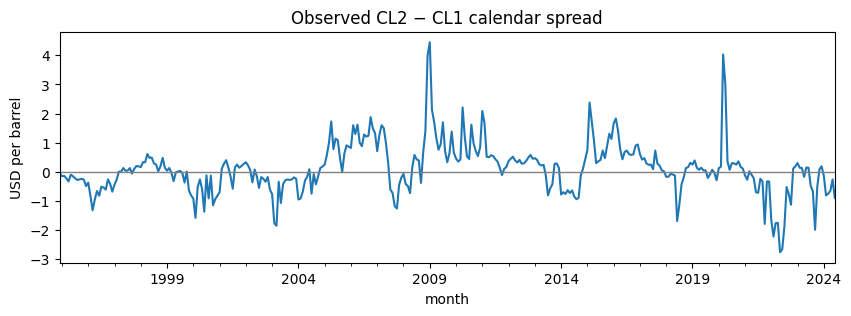

Development-sample correlations with next-month change:


,spread,spread_change,inventory_growth,ip_growth,target
spread,1.000,0.303,0.184,-0.208,-0.304
spread_change,0.303,1.000,-0.080,0.053,-0.055
inventory_growth,0.184,-0.080,1.000,-0.073,-0.124
ip_growth,-0.208,0.053,-0.073,1.000,-0.035
target,-0.304,-0.055,-0.124,-0.035,1.000


In [ ]:
f=monthly[['CL1','CL2']].copy()
f['spread']=monthly['CL2']-monthly['CL1']
f['spread_change']=f['spread'].diff()
f['inventory_growth']=100*np.log(monthly['Inventories']).diff().shift(2)
f['ip_growth']=100*np.log(monthly['IndustrialProduction Index']).diff().shift(2)
f['target']=(f['spread'].shift(-1)-f['spread'])
f['spread_next']=f['spread'].shift(-1)
f['target_month']=f.index+1
frame=f.dropna(subset=FEATURES+['target','spread_next','CL1','CL2']).copy()
assert not frame.empty
assert (frame['target_month']==frame.index+1).all()
assert np.allclose(frame['target'],frame['spread_next']-frame['spread'])
assert frame.index.equals(pd.period_range(frame.index.min(),frame.index.max(),freq='M'))
print(f'Complete labelled targets: {len(frame)} | development: {(frame.target_month<TEST_START).sum()} | evaluation: {(frame.target_month>=TEST_START).sum()}')
assert len(frame)==351 and (frame.target_month>=TEST_START).sum()==66, 'Dataset differs from validated supplied historical project'
fig,ax=plt.subplots(figsize=(10,3)); monthly.eval('CL2-CL1').plot(ax=ax); ax.axhline(0,color='grey',lw=1)
ax.set(title='Observed CL2 − CL1 calendar spread',ylabel='USD per barrel');plt.show()
print('Development-sample correlations with next-month change:')
dev=frame[frame.target_month<TEST_START]
display(dev[FEATURES+['target']].corr().round(3))

## 3. OLS and chronological one-step forecasts
OLS is estimated *with an intercept*, by minimising squared errors. No predictor uses a future target. For forecast origin \(t\), training includes only outcomes known through \(t\). The model is re-estimated every month. We test 2-, 3- and 4-predictor predeclared specifications, plus zero-change and expanding-mean benchmarks. The main model is chosen **only on 2015–2018 validation**.

In [ ]:
def predict_ols(train, current, predictors):
    X=sm.add_constant(train[predictors],has_constant='add')
    model=sm.OLS(train['target'],X).fit()
    new=sm.add_constant(pd.DataFrame([current[predictors]]),has_constant='add')
    return float(model.predict(new).iloc[0])

def rolling_predictions(frame, model, periods, window=None):
    out=[]
    for idx in periods:
        pos=frame.index.get_loc(idx)
        train=frame.iloc[max(0,pos-window) if window else 0:pos]
        assert len(train)>=60
        assert pd.Period(train['target_month'].iloc[-1],freq='M')<=idx, 'Future target leaked into training'
        current=frame.loc[idx]
        if model in OLS_SPECS:
            yhat=predict_ols(train,current,OLS_SPECS[model])
        elif model=='Zero change': yhat=0.0
        elif model=='Expanding mean': yhat=float(train['target'].mean())
        else: raise ValueError(model)
        out.append({'model':model,'origin':str(idx),'target_month':str(idx+1),'actual':float(current['target']),
                    'prediction':yhat,'spread':float(current['spread']), 'CL1':float(current['CL1']),'CL2':float(current['CL2'])})
    return pd.DataFrame(out)

def score(panel):
    e=panel.actual-panel.prediction
    return {'n':len(e),'RMSE':float(np.sqrt(np.mean(e**2))),'MAE':float(np.mean(abs(e))),
            'MSE':float(np.mean(e**2))}

validation_periods=frame.index[(frame.target_month>=VALID_START)&(frame.target_month<=VALID_END)]
validation={m:rolling_predictions(frame,m,validation_periods) for m in [*OLS_SPECS,'Zero change','Expanding mean']}
valid_scores=pd.DataFrame({m:score(p) for m,p in validation.items()}).T.sort_values('RMSE')
display(valid_scores.round(5))
selected_ols=min(OLS_SPECS,key=lambda m:score(validation[m])['MSE'])
print('Selected OLS from pre-test validation:',selected_ols)
assert selected_ols=='OLS4', 'Selected specification differs from the previously validated historical project' 

,n,RMSE,MAE,MSE
OLS4,48.0,0.43863,0.28215,0.19240
OLS3,48.0,0.43980,0.28265,0.19342
OLS2,48.0,0.44060,0.27942,0.19413
Zero change,48.0,0.46275,0.31000,0.21413
Expanding mean,48.0,0.46367,0.31072,0.21499


Selected OLS from pre-test validation: OLS4


## 4. ARMA as a traditional time-series comparator (not a machine-learning model)
A simple ARMA(1,1) is an optional traditional comparison. The stationary **level vs change representation** is selected from pre-2015 observations only (ADF and KPSS). The same forecast origins and target months are used as OLS. If the numerical optimisation fails, the notebook reports it instead of silently substituting a prediction.

In [ ]:
initial=frame[frame.target_month<VALID_START]
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    level_adf=adfuller(initial['spread_next'],maxlag=12,regression='c',autolag='AIC')[1]
    level_kpss=kpss(initial['spread_next'],regression='c',nlags='auto')[1]
arma_representation='level' if level_adf<.05 and level_kpss>=.05 else 'change'
print('ARMA representation:',arma_representation,'; pre-2015 ADF p=',round(level_adf,4),'KPSS p=',round(level_kpss,4))

def rolling_arma(frame,periods,order=(1,1),representation=arma_representation):
    rec=[]
    for period in periods:
        pos=frame.index.get_loc(period); train=frame.iloc[:pos]
        assert train.target_month.iloc[-1]<=period
        series=train['spread_next' if representation=='level' else 'target'].to_numpy(float)
        last_error=None
        for method in ['lbfgs','bfgs']:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    fit=ARIMA(series,order=(order[0],0,order[1]),trend='c',enforce_stationarity=True,enforce_invertibility=True).fit(method_kwargs={'method':method,'maxiter':500,'disp':0})
                if not fit.mle_retvals.get('converged',False):raise RuntimeError('ARMA optimiser did not converge')
                value=float(fit.forecast(1)[0]); break
            except Exception as exc: last_error=exc
        else: raise RuntimeError(f'ARMA failed at {period}: {last_error}')
        row=frame.loc[period]
        forecast=value-float(row['spread']) if representation=='level' else value
        rec.append({'model':'ARMA(1,1)','origin':str(period),'target_month':str(period+1), 'actual':float(row['target']), 'prediction':forecast,'spread':float(row['spread']), 'CL1':float(row['CL1']),'CL2':float(row['CL2'])})
    return pd.DataFrame(rec)

# To reproduce the selected ARMA order exactly, first compare (1,0), (0,1), (1,1)
# using the validation period; uncomment ONLY if rerunning the full selection:
# arma_validation={o:rolling_arma(frame,validation_periods,o) for o in [(1,0),(0,1),(1,1)]}
# selected_arma_order=min(arma_validation,key=lambda o:score(arma_validation[o])['MSE'])
selected_arma_order=(1,1)  # Documented fixed comparison; OLS remains the main focus.
print('ARMA comparison order:',selected_arma_order)

ARMA representation: change ; pre-2015 ADF p= 0.0 KPSS p= 0.0246
ARMA comparison order: (1, 1)


## 5. Later historical forecasts and **fair benchmark comparison**
All models forecast the same 66 target months from January 2019 through June 2024. We compare RMSE and MAE in USD/barrel and \(1-MSE_{model}/MSE_{zero}\). A smaller RMSE does not imply a trading profit.

,n,RMSE,MAE,MSE improvement vs zero (%)
OLS2,66.0,0.7545,0.4394,10.7145
OLS3,66.0,0.7552,0.4503,10.5606
OLS4,66.0,0.7604,0.4800,9.3091
Zero change,66.0,0.7985,0.4598,0.0000
Expanding mean,66.0,0.7998,0.4610,-0.3199


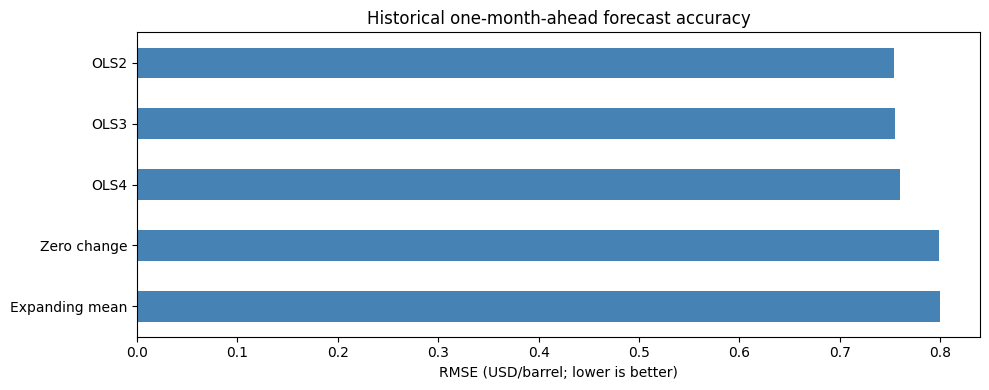

In [ ]:
test_periods=frame.index[frame.target_month>=TEST_START]
all_models=[*OLS_SPECS,'Zero change','Expanding mean']
test_panels={m:rolling_predictions(frame,m,test_periods) for m in all_models}
# ARMA fitting is comparatively slow because it is re-estimated for every month.
INCLUDE_ARMA=False  # Set True to run the slower secondary ARMA model (optional)
if INCLUDE_ARMA:
    test_panels['ARMA(1,1)']=rolling_arma(frame,test_periods,selected_arma_order)
base_mse=score(test_panels['Zero change'])['MSE']
results=pd.DataFrame({m:{**score(p),'MSE improvement vs zero (%)':100*(1-score(p)['MSE']/base_mse)}
                      for m,p in test_panels.items()}).T.sort_values('RMSE')
display(results[['n','RMSE','MAE','MSE improvement vs zero (%)']].round(4))
assert len(test_panels[selected_ols])==66
fig,ax=plt.subplots(figsize=(10,4))
results['RMSE'].sort_values().plot(kind='barh',ax=ax,color='steelblue');ax.invert_yaxis()
ax.set(xlabel='RMSE (USD/barrel; lower is better)',title='Historical one-month-ahead forecast accuracy')
plt.tight_layout();plt.show()

## 6. Regression interpretation and standard econometric diagnostics
Fit OLS4 only on **pre-2019 development data** for the explanatory coefficient table. The forecast experiment itself refits at every origin. HAC (Newey–West) standard errors account approximately for serial correlation/heteroskedasticity in inference; they do not change OLS coefficients or cure omitted variables. ADF has the unit-root null; KPSS has a stationarity null.

,coefficient,HAC SE,HAC p-value
const,0.05408,0.03457,0.11887
spread,-0.19858,0.04194,0.00000
spread_change,0.04484,0.10496,0.66956
inventory_growth,-0.03067,0.02227,0.16951
ip_growth,-0.08320,0.09244,0.36885


,p-value
Breusch–Godfrey p (12),0.17594
Breusch–Pagan p,0.00053
ARCH LM p (6),0.00397
CUSUM p,0.07059
ADF target p,0.00000
KPSS target p,0.10000


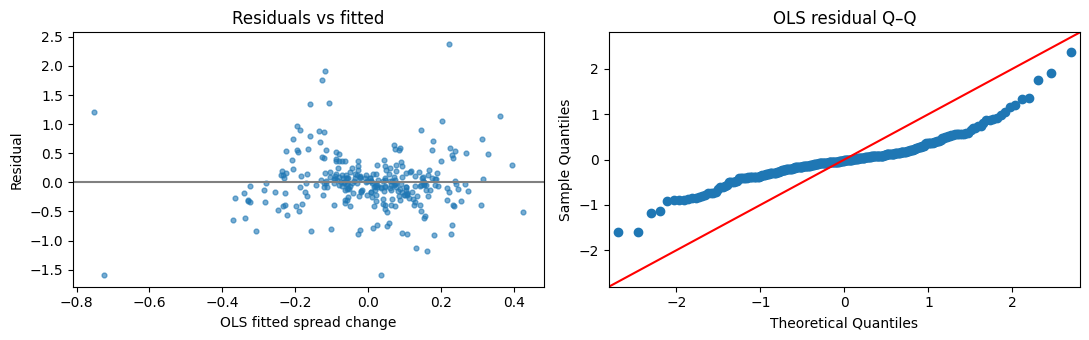

Interpret coefficients as conditional associations, not causal effects.


In [ ]:
cols=OLS_SPECS[selected_ols]
X=sm.add_constant(dev[cols],has_constant='add')
ols=sm.OLS(dev.target,X).fit()
robust=ols.get_robustcov_results(cov_type='HAC',maxlags=6)
coef=pd.DataFrame({'coefficient':robust.params,'HAC SE':robust.bse,'HAC p-value':robust.pvalues},index=X.columns)
display(coef.round(5))
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    diagnostics={
        'Breusch–Godfrey p (12)':acorr_breusch_godfrey(ols,nlags=12)[1],
        'Breusch–Pagan p':het_breuschpagan(ols.resid,ols.model.exog)[1],
        'ARCH LM p (6)':het_arch(ols.resid,nlags=6)[1],
        'CUSUM p':breaks_cusumolsresid(ols.resid,ddof=int(ols.df_model)+1)[1],
        'ADF target p':adfuller(dev.target,maxlag=12,autolag='AIC')[1],
        'KPSS target p':kpss(dev.target,nlags='auto')[1],
    }
display(pd.Series(diagnostics,name='p-value').to_frame().round(5))
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].scatter(ols.fittedvalues,ols.resid,s=12,alpha=.6);axes[0].axhline(0,color='grey');axes[0].set(xlabel='OLS fitted spread change',ylabel='Residual',title='Residuals vs fitted')
sm.qqplot(ols.resid,line='45',ax=axes[1]);axes[1].set(title='OLS residual Q–Q')
plt.tight_layout();plt.show()
print('Interpret coefficients as conditional associations, not causal effects.')

## 7. Uncertainty in improvement — paired moving-block bootstrap
A 95% interval is generated by resampling paired monthly squared-loss differences in consecutive six-month circular blocks. This uses the **existing forecasts** and does not account for re-tuning, model search or structural shifts.

In [ ]:
p=test_panels[selected_ols]
base=test_panels['Zero change']
assert p.target_month.tolist()==base.target_month.tolist()
d=((base.actual-base.prediction)**2-(p.actual-p.prediction)**2).to_numpy()
rng=np.random.default_rng(SEED); n=len(d); block=6; reps=2000
boot=np.empty(reps)
for j in range(reps):
    starts=rng.integers(0,n,size=int(np.ceil(n/block)))
    indices=np.concatenate([(s+np.arange(block))%n for s in starts])[:n]
    boot[j]=d[indices].mean()
print('Mean squared-loss benefit (USD/barrel)^2:',round(d.mean(),5))
print('95% moving-block interval:',np.round(np.quantile(boot,[.025,.975]),5))
print('Interval includes zero:',np.quantile(boot,.025)<=0<=np.quantile(boot,.975))

Mean squared-loss benefit (USD/barrel)^2: 0.05935
95% moving-block interval: [-0.04041  0.19192]
Interval includes zero: True


## 8. Trading decision illustration **versus baselines**
**Important limitation:** The following is a *continuous-spread change proxy*, **not verified futures P&L**. The project lacks contract IDs, roll timing, executable bid/ask quotes, margin and collateral returns. If predicted spread change exceeds +$0.10, the illustration is long CL2/short CL1; below −$0.10, the opposite; otherwise flat. Each active month is a newly entered and closed two-leg position, so four one-way transactions are charged. We compare the selected OLS signal, an always-long-spread baseline, and flat exposure. Graphs start at 100 solely for visual comparison, not as investable wealth indices.

,total_proxy_usd_per_bbl,active_months
strategy,,
Always flat,0.00,0
Always long spread,-7.81,66
OLS4,3.30,38


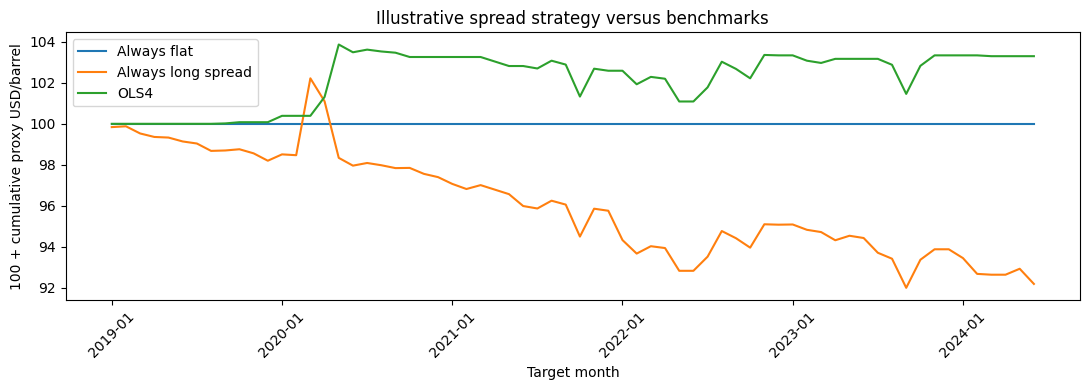

CAUTION: baseline and OLS are proxy spread-change payoffs, not investable total returns.


In [ ]:
COST_LEG_WAY=0.025  # USD per barrel per leg per one-way transaction; assumption, not observed cost
BAND=0.10
p=test_panels[selected_ols].copy().sort_values('target_month')
actual=p.actual.to_numpy(float)
def proxy_path(signal,name,cost=COST_LEG_WAY):
    q=np.where(signal>BAND,1,np.where(signal< -BAND,-1,0))
    gross=q*actual
    costs=4*cost*(q!=0)
    net=gross-costs
    return pd.DataFrame({'month':p.target_month,'strategy':name,'position':q,'net':net,'cum_dollars':np.cumsum(net),'index_100':100+np.cumsum(net)})
long_short=proxy_path(p.prediction.to_numpy(float),selected_ols)
always_long=proxy_path(np.full(len(p),np.inf),'Always long spread')
flat=proxy_path(np.zeros(len(p)),'Always flat')
trading=pd.concat([long_short,always_long,flat],ignore_index=True)
trading_summary=trading.groupby('strategy').agg(total_proxy_usd_per_bbl=('net','sum'),active_months=('position',lambda q:int((q!=0).sum())))
display(trading_summary.round(3))
fig,ax=plt.subplots(figsize=(11,4))
for name,grp in trading.groupby('strategy'):
    ax.plot(grp['month'].astype(str),grp['index_100'],label=name)
ax.set(title='Illustrative spread strategy versus benchmarks',ylabel='100 + cumulative proxy USD/barrel',xlabel='Target month')
ax.set_xticks(range(0,len(p),12));ax.legend();plt.xticks(rotation=45);plt.tight_layout();plt.show()
print('CAUTION: baseline and OLS are proxy spread-change payoffs, not investable total returns.')

## 9. Robustness: longer assumed release delay and shorter estimation window
Robustness checks must not be used to select whichever variant performed best *after* inspecting the test. The main OLS4 validation choice remains frozen. Changing the release delay from two months to three requires reconstructing the affected features and eligible origins; a 120-month rolling window changes only the training sample.

In [ ]:
rolling120=rolling_predictions(frame,selected_ols,test_periods,window=120)
print('Expanding OLS:',score(test_panels[selected_ols]))
print('120-month OLS:',score(rolling120))
lag3=f.copy()
lag3['inventory_growth']=100*np.log(monthly['Inventories']).diff().shift(3)
lag3['ip_growth']=100*np.log(monthly['IndustrialProduction Index']).diff().shift(3)
lag3=lag3.dropna(subset=FEATURES+['target','spread_next','CL1','CL2'])
lag3_test=lag3.index[lag3.target_month>=TEST_START]
lag3_pred=rolling_predictions(lag3,selected_ols,lag3_test)
print('3-month delay OLS:',score(lag3_pred))
print('Different delayed-feature choices describe sensitivity; publication dates remain unverified.')

Expanding OLS: {'n': 66, 'RMSE': 0.7604180449919079, 'MAE': 0.48002846956105494, 'MSE': 0.5782356031493152}
120-month OLS: {'n': 66, 'RMSE': 0.774532987014484, 'MAE': 0.49724307908910154, 'MSE': 0.599901347973579}


3-month delay OLS: {'n': 66, 'RMSE': 0.7842401967514799, 'MAE': 0.4706778476230698, 'MSE': 0.6150326862007999}
Different delayed-feature choices describe sensitivity; publication dates remain unverified.


## 10. Group presentation defence
**What we did:** We used only the professor-supplied monthly WTI CL1/CL2, inventory and industrial-production series. We chose the dollar calendar-spread change as the forecasting object because relative term-structure movements may be easier to predict than outright price returns. We transformed delayed inventory and IP into log growth rates, without scaling the two spreads. We compared a short, theory-motivated OLS ladder with ARMA and simple zero/mean forecasts, selected the OLS specification in a pre-2019 validation window, and evaluated later historical forecasts with diagnostics, uncertainty and a qualified trading illustration.

**What we cannot claim:** Correlation proves causality; the chosen model always works; a 9% squared-error improvement equals 9% trading profit; our CL2–CL1 proxy equals actual held-contract P&L; the assumed publication lags reconstruct exact historical information vintages; or a revised model receives a new untouched holdout simply because it is packaged as a notebook.

**Submission:** This `.ipynb` is the **one program file**. The four relevant columns of the professor's original workbook are embedded with a checksum, so this notebook works without any separate dataset. If the portal asks for the original data, submit that workbook separately as a data attachment. No `src/` directory or extra scripts are required. Run **Kernel → Restart & Run All** to verify execution before uploading.